# RQ1: is the raw metabolome predictive at all?

A walkthrough of `scripts/run_permutation.py`, which calls
`metabo.evaluation.permutation_null`: one stratified cross-validation with fixed
hyperparameters (no inner tuning) gives the observed AUROC; the same cross-validation is
repeated with the outcome labels shuffled, many times, to build a null distribution.
`p = (1 + #{null >= observed}) / (n_perm + 1)`.

`n_perm` is reduced to 200 here (the study uses 1000) for speed. The data in `data/` is
purely synthetic, drawn from chosen statistical distributions, not derived from any real
data (see `00_build_data.ipynb`).


In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

REPO_ROOT = Path.cwd().parent
SRC_DIR = REPO_ROOT / "src"
DATA_DIR = REPO_ROOT / "data"
sys.path.insert(0, str(SRC_DIR))
sys.path.insert(0, str(SRC_DIR / "analysis"))
# So a subprocess started from here (python "scripts/some_script.py") can "from metabo
# import ..." too, exactly as if the package had been pip installed.
os.environ["PYTHONPATH"] = str(SRC_DIR)
os.environ["METABO_DATA_DIR"] = str(DATA_DIR)
os.environ["METABO_RESULTS_DIR"] = str(Path.cwd() / "results")

# data/ is not shipped with the repo -- generate it on first use, same recipe as
# 00_build_data.ipynb, if it is not already there.
_RENAMED = {
    "datacorr_6m6y18mMw1w24_final.csv": "synthetic_raw_metabolome.csv",
    "target_for_metabolites_ml.csv": "synthetic_targets.csv",
    "metabolites_6m_for_ml.csv": "synthetic_metabolites_6m.csv",
    "metabolites_18m_for_ml.csv": "synthetic_metabolites_18m.csv",
    "metabolites_6y_for_ml.csv": "synthetic_metabolites_6y.csv",
}
if not all((DATA_DIR / new).exists() for new in _RENAMED.values()):
    import subprocess
    import shutil
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run([sys.executable, str(SRC_DIR / "scripts" / "make_synthetic_data.py"),
                    "--outdir", str(DATA_DIR), "--force"], check=True, capture_output=True)
    subprocess.run([sys.executable, str(SRC_DIR / "scripts" / "build_inputs.py"),
                    "--source", str(DATA_DIR / "datacorr_6m6y18mMw1w24_final.csv"),
                    "--outdir", str(DATA_DIR)], check=True, capture_output=True)
    for old, new in _RENAMED.items():
        shutil.move(str(DATA_DIR / old), str(DATA_DIR / new))
    print("generated data/ (not shipped with the repo)")
# The synthetic data files are named distinctly from metabo.config's own default filenames,
# so every script that reads them -- in this process or in a subprocess started from here --
# is told explicitly which files to use.
os.environ["METABO_SOURCE"] = str(DATA_DIR / "synthetic_raw_metabolome.csv")
os.environ["METABO_TARGET_FILE"] = str(DATA_DIR / "synthetic_targets.csv")
os.environ["METABO_METAB_6M"] = str(DATA_DIR / "synthetic_metabolites_6m.csv")
os.environ["METABO_METAB_18M"] = str(DATA_DIR / "synthetic_metabolites_18m.csv")
os.environ["METABO_METAB_6Y"] = str(DATA_DIR / "synthetic_metabolites_6y.csv")
# The synthetic metabolites are named generically (metabolite001, ...), not with real
# chemical nomenclature, so the attribution scripts are told which generic name is the
# planted fish-oil marker (and its weaker parent compound).
os.environ["METABO_FISHOIL_MARKER"] = "metabolite001"
os.environ["METABO_FISHOIL_MARKER_PARENT"] = "metabolite002"
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("NUMBA_THREADING_LAYER", "workqueue")

# Reduced from the study's settings (1000 bootstraps/permutations, all five embedding
# dimensions, ten repeats) so every cell below finishes in well under a minute.
os.environ["METABO_N_BOOTSTRAP"] = "100"
os.environ["METABO_N_PERMUTATION"] = "200"
os.environ["METABO_EMBED_DIMS"] = "2 16"
os.environ["METABO_VAE_MAX_EPOCHS"] = "40"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from metabo import config, data_io, evaluation

print("embedding dims used here:", config.EMBED_DIMS, "(study default: 2 3 4 8 16)")


embedding dims used here: [2, 16] (study default: 2 3 4 8 16)


In [2]:
X_6m = data_io.load_metabolites("6m")
targets = data_io.load_targets()

rows = []
for outcome in ["sex", "fishoil", "vitd"]:
    X, y = data_io.align(X_6m, targets[outcome])
    res = evaluation.permutation_null(X, y, "raw", 0, "lr", random_state=config.SEED)
    rows.append({"outcome": outcome, **res})

perm_results = pd.DataFrame(rows)
perm_results


,outcome,obs_auroc,null_mean,null_p95,p_value,n_perm
0,sex,0.758669,0.503950,0.585863,0.004975,200
1,fishoil,0.735026,0.497594,0.572035,0.004975,200
2,vitd,0.507551,0.505376,0.591750,0.492537,200


`sex` and `fishoil` were built with planted signal, so both should reject the null
(`p_value` well below 0.05, `obs_auroc` well above `null_mean`); `vitd` has no planted signal,
so its `p_value` should look unremarkable, close to uniform on (0, 1).

## The null distribution for one outcome


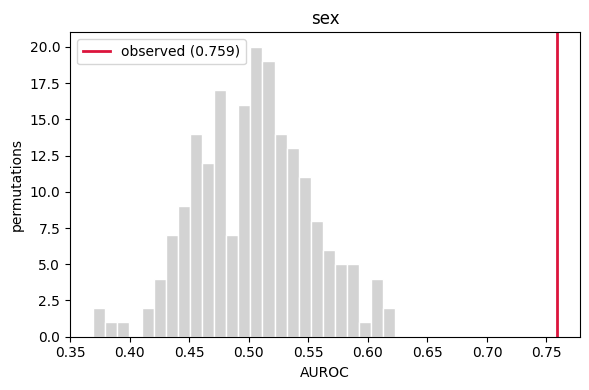

In [3]:
OUTCOME = "sex"
X, y = data_io.align(X_6m, targets[OUTCOME])

n_perm = int(os.environ["METABO_N_PERMUTATION"])
rng = np.random.default_rng(config.SEED)
Xv = y_values = None  # not used directly; evaluation.permutation_null does the CV internally

# Rerun the same call, but keep the null draws this time by reimplementing the one loop
# (permutation_null itself only returns the summary, not the full null array).
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

def cv_auroc(yy):
    skf = StratifiedKFold(5, shuffle=True, random_state=config.SEED)
    oof = np.full(len(yy), np.nan)
    for tr, te in skf.split(X.values, yy):
        pipe = evaluation.build_pipeline("raw", 0, "lr", config.SEED, clf_n_jobs=1)
        pipe.fit(X.values[tr], yy[tr])
        oof[te] = pipe.predict_proba(X.values[te])[:, 1]
    return roc_auc_score(yy, oof)

yv = y.values
obs = cv_auroc(yv)
null = np.array([cv_auroc(rng.permutation(yv)) for _ in range(n_perm)])

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(null, bins=25, color="lightgray", edgecolor="white")
ax.axvline(obs, color="crimson", linewidth=2, label=f"observed ({obs:.3f})")
ax.set_xlabel("AUROC"); ax.set_ylabel("permutations"); ax.set_title(OUTCOME)
ax.legend()
fig.tight_layout()


## Next steps

- Run the full grid as a batch job (all 14 outcomes, every timepoint, 1000 permutations,
  results written to `results/`, resume-safe if run again):

```bash
cd ../src
export METABO_DATA_DIR=../data METABO_RESULTS_DIR=../notebooks/results
python scripts/run_permutation.py --timepoints 6m 18m 6y --n_perm 1000 --jobs 8
```

- `analysis/pair_statistics.py` takes the resulting per-outcome p-values and adds a
  Benjamini-Hochberg correction across all tests, matching the study's Table 3.
